In [495]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math

In [496]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error

In [497]:
from keras.models import Sequential

In [498]:
from keras.layers import Dense
from keras.layers import LSTM

In [499]:
#df_vitals = pd.read_csv('vitals2_lstm.csv')
#df_vitals = pd.read_csv('combined_vitals.csv')
df_vitals = pd.read_csv('vitals_combined_interpolated.csv')

In [500]:
df_vitals.head()

,patient_uuid,reading_date,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.85394
1,1127912,2019-11-20,0,92.000000,120.50000
2,1127912,2019-11-21,0,87.000000,131.75000
3,1127912,2019-11-22,0,89.000000,127.00000
4,1127912,2019-11-23,0,93.000000,109.50000


In [501]:
df_vitals.rename(columns = {'reading_date':'timestamp'}, inplace = True)
df_vitals['timestamp'] = pd.to_datetime(df_vitals['timestamp'], errors='coerce')
df_vitals

,patient_uuid,timestamp,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.853940
1,1127912,2019-11-20,0,92.000000,120.500000
2,1127912,2019-11-21,0,87.000000,131.750000
3,1127912,2019-11-22,0,89.000000,127.000000
4,1127912,2019-11-23,0,93.000000,109.500000
...,...,...,...,...,...
127630,99814066,2020-01-08,0,97.283923,112.820825
127631,99814066,2020-01-09,0,93.460395,110.853570
127632,99814066,2020-01-10,0,89.636867,108.886316
127633,99814066,2020-01-11,0,85.813338,106.919062


In [502]:
# Drops batches containing less than 30 observations.
df_recordings_per_patient = df_vitals.groupby(['patient_uuid', 'batch']).count().reset_index()
low_batches = df_recordings_per_patient[(df_recordings_per_patient.HR <= 30)][['patient_uuid','batch']]
for i in range(len(low_batches)):
    low_patient = low_batches.patient_uuid.iloc[i]
    low_batch = low_batches.batch.iloc[i]
    df_vitals.drop(df_vitals[(df_vitals.patient_uuid == low_patient) & (df_vitals.batch == low_batch)].index, inplace=True)

In [503]:
#df_vitals['reading_date'] = pd.to_datetime(df_vitals['reading_date'],errors='coerce')
df_vitals.head()

,patient_uuid,timestamp,batch,HR,SBP
0,1127912,2019-11-19,0,87.261064,124.85394
1,1127912,2019-11-20,0,92.000000,120.50000
2,1127912,2019-11-21,0,87.000000,131.75000
3,1127912,2019-11-22,0,89.000000,127.00000
4,1127912,2019-11-23,0,93.000000,109.50000


In [504]:
#df_vitals=df_vitals[(df_vitals.timestamp>'2018-10-01')] # &(df_vitals.timestamp<'2019-11-11')
df_vitals=df_vitals[(df_vitals.timestamp >= '2018-10-01') & (df_vitals.timestamp <= '2020-01-14')]
# remove all na entries
#df_vitals=df_vitals[~df_vitals['DBP'].isna()]
#df_vitals=df_vitals[~df_vitals['SBP'].isna()]
#df_vitals=df_vitals[~df_vitals['HR'].isna()]

In [505]:
print(df_vitals.count())

patient_uuid    121156
timestamp       121156
batch           121156
HR              121156
SBP             121156
dtype: int64


In [506]:
#df_vitals.to_csv('df_vitals_combined_int.csv', encoding='utf-8')

In [507]:
# Systolic Blood Pressure. 
df_vitals_sbp = df_vitals[['timestamp','patient_uuid','SBP']] # 'SBP' 'DBP'
df_vitals_sbp

,timestamp,patient_uuid,SBP
0,2019-11-19,1127912,124.853940
1,2019-11-20,1127912,120.500000
2,2019-11-21,1127912,131.750000
3,2019-11-22,1127912,127.000000
4,2019-11-23,1127912,109.500000
...,...,...,...
127625,2019-03-18,99726731,130.000000
127626,2019-03-19,99726731,115.000000
127627,2019-03-20,99726731,116.368667
127628,2019-03-21,99726731,147.000000


In [508]:
# Also, Heart rate. 
df_vitals_hr = df_vitals[['timestamp','patient_uuid','HR']] # 'SBP' 'DBP'
df_vitals_hr

,timestamp,patient_uuid,HR
0,2019-11-19,1127912,87.261064
1,2019-11-20,1127912,92.000000
2,2019-11-21,1127912,87.000000
3,2019-11-22,1127912,89.000000
4,2019-11-23,1127912,93.000000
...,...,...,...
127625,2019-03-18,99726731,60.000000
127626,2019-03-19,99726731,59.000000
127627,2019-03-20,99726731,65.526797
127628,2019-03-21,99726731,56.000000


In [509]:
patients = df_vitals_sbp.patient_uuid.unique()#df_vitals_sbp.patient_uuid.unique()
patients.size

883

In [510]:
#df_select_uuid = df_vitals_sbp # 
df_select_uuid = df_vitals_sbp.loc[df_vitals_sbp['patient_uuid'] == 73939445] #1519674 #8989080 # 82591262 # 54404566 # 73939445 # 9448847

In [511]:
df_SBP = df_select_uuid[['SBP']]

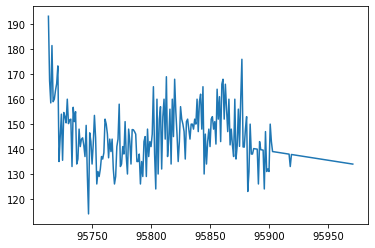

In [512]:
plt.plot(df_SBP)
plt.show()

In [513]:
# fix random seed for reproducibility
np.random.seed(7)

In [514]:
dataset = df_SBP.astype('float32')
dataset

,SBP
95713,193.250000
95714,167.333328
95715,158.500000
95716,181.500000
95717,159.000000
...,...
95967,134.271408
95968,134.197433
95969,134.123459
95970,134.049484


In [515]:
# normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

In [516]:
# split into train and test sets
train_size = len(dataset) - 7
test_size = 7#len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
print(len(train), len(test))

252 7


In [517]:
# convert an array of values into a dataset matrix
def create_dataset(dataset, look_back=1):
	dataX, dataY = [], []
	for i in range(len(dataset)-look_back-1):
		a = dataset[i:(i+look_back), 0]
		dataX.append(a)
		dataY.append(dataset[i + look_back, 0])
	return np.array(dataX), np.array(dataY)

In [518]:
# reshape into X=t and Y=t+1
look_back = 3 # 1 look_back must be < 7
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

In [519]:
# reshape input to be [samples, time steps, features]
#trainX = np.reshape(trainX, (trainX.shape[0], 1, trainX.shape[1])) #no time steps
#testX = np.reshape(testX, (testX.shape[0], 1, testX.shape[1]))     #no time steps

trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1)) 
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

In [520]:
# create and fit the LSTM network
batch_size = 1
model = Sequential()
#model.add(LSTM(4, batch_input_shape=(batch_size, look_back, 1), stateful=True)) #time steps, memory between batches
model.add(LSTM(4, input_shape=(look_back, 1))) #time steps, no memory
# model.add(LSTM(4, input_shape=(1, look_back))) #no time steps, no memory
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])

#for i in range(3): # range(100)
#	model.fit(trainX, trainY, epochs=1, batch_size=batch_size, verbose=2, shuffle=False)
#	model.reset_states()

model.fit(trainX, trainY, epochs=30, batch_size=1, verbose=2) # epochs=10, epochs=100, epochs=30, epochs=3,

Epoch 1/30
 - 1s - loss: 0.1063 - mae: 0.2601
Epoch 2/30
 - 0s - loss: 0.0194 - mae: 0.1109
Epoch 3/30
 - 0s - loss: 0.0185 - mae: 0.1078
Epoch 4/30
 - 0s - loss: 0.0175 - mae: 0.1059
Epoch 5/30
 - 0s - loss: 0.0167 - mae: 0.1035
Epoch 6/30
 - 0s - loss: 0.0161 - mae: 0.1012
Epoch 7/30
 - 0s - loss: 0.0155 - mae: 0.0991
Epoch 8/30
 - 0s - loss: 0.0149 - mae: 0.0949
Epoch 9/30
 - 0s - loss: 0.0146 - mae: 0.0965
Epoch 10/30
 - 0s - loss: 0.0144 - mae: 0.0965
Epoch 11/30
 - 0s - loss: 0.0140 - mae: 0.0938
Epoch 12/30
 - 0s - loss: 0.0135 - mae: 0.0921
Epoch 13/30
 - 0s - loss: 0.0133 - mae: 0.0901
Epoch 14/30
 - 0s - loss: 0.0132 - mae: 0.0895
Epoch 15/30
 - 0s - loss: 0.0128 - mae: 0.0874
Epoch 16/30
 - 0s - loss: 0.0131 - mae: 0.0892
Epoch 17/30
 - 0s - loss: 0.0127 - mae: 0.0870
Epoch 18/30
 - 0s - loss: 0.0127 - mae: 0.0873
Epoch 19/30
 - 0s - loss: 0.0127 - mae: 0.0865
Epoch 20/30
 - 0s - loss: 0.0124 - mae: 0.0839
Epoch 21/30
 - 0s - loss: 0.0127 - mae: 0.0848
Epoch 22/30
 - 0s - lo

In [521]:
# make predictions
#trainPredict = model.predict(trainX, batch_size=batch_size) #memory between batches
trainPredict = model.predict(trainX) # no memory
#model.reset_states() #memory between batches
#testPredict = model.predict(testX, batch_size=batch_size) #memory between bathes
testPredict = model.predict(testX) # no memory

# invert predictions
trainPredict = scaler.inverse_transform(trainPredict)
trainY = scaler.inverse_transform([trainY])
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])

# calculate root mean squared error
trainScore = np.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = np.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

Train Score: 8.75 RMSE
Test Score: 3.30 RMSE


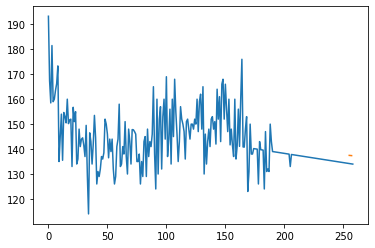

In [522]:
# shift train predictions for plotting
#trainPredictPlot = np.empty_like(dataset)
#trainPredictPlot[:, :] = np.nan
#trainPredictPlot[look_back:len(trainPredict)+look_back, :] = trainPredict

# shift test predictions for plotting
testPredictPlot = np.empty_like(dataset)
testPredictPlot[:, :] = np.nan
testPredictPlot[len(trainPredict)+(look_back*2)+1:len(dataset)-1, :] = testPredict

# plot baseline and predictions
plt.plot(scaler.inverse_transform(dataset))

#plt.plot(dataset)
#plt.plot(trainPredictPlot)
plt.plot(testPredictPlot)
plt.show()

In [523]:
# Select UUID
df_select_uuid = df_vitals_sbp.loc[df_vitals_sbp['patient_uuid'] == 73939445] #1519674 #8989080 # 82591262 # 54404566 # 73939445 # 9448847

In [524]:
# fix random seed for reproducibility
np.random.seed(7)
epoch_count = 3

# Select SBP
df_SBP = df_select_uuid[['SBP']]
dataset = df_SBP.astype('float32')

# normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

# split into train and test sets
train_size = len(dataset) - 7
test_size = 7#len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
print('Patient: ', df_select_uuid.iloc[0]['patient_uuid'], 'Train: ', len(train), 'Test: ', len(test))

# reshape into X=t and Y=t+1
look_back = 3 # 1 look_back must be < 7
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1)) 
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

# create and fit the LSTM network
batch_size = 1
model = Sequential()
model.add(LSTM(4, input_shape=(look_back, 1))) #time steps, no memory
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])
history = model.fit(trainX, trainY, epochs=epoch_count, batch_size=1, verbose=0) # epochs=10, epochs=100, epochs=30, epochs=3,

# make predictions
testPredict = model.predict(testX) # no memory

# invert predictions
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])

# calculate root mean squared error
print('Train Score: %.2f RMSE' % (trainScore))
testScore = np.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))
print('MAPE: %2f ' % history.history['mae'][epoch_count-1])

Patient:  73939445 Train:  252 Test:  7
Train Score: 8.75 RMSE
Test Score: 8.94 RMSE
MAPE: 0.105025 


In [525]:
def split_sequence(sequence, n_steps_in, n_steps_out):
	X, y = list(), list()
	for i in range(len(sequence)):
		# find the end of this pattern
		end_ix = i + n_steps_in
		out_end_ix = end_ix + n_steps_out
		# check if we are beyond the sequence
		if out_end_ix > len(sequence):
			break
		# gather input and output parts of the pattern
		seq_x, seq_y = sequence[i:end_ix], sequence[end_ix:out_end_ix]
		X.append(seq_x)
		y.append(seq_y)
	return array(X), array(y)


In [ ]:
def forecast_accuracy(forecast, actual):
    """
     Calculates accuracy by calculating mean absolute percentage error, mean absolute error, 
     and root-mean-squared error.
    
    forecast: forecast dataframe containing the results from a model.
    actual  : test set of a particular patient, with same dates as the forecast dataframe.
    
    output  : mape: mean absolute percentage error
              mae : mean absolute error
              rsme: root mean square error
    """
    forecast = forecast.values
    mape = np.mean(np.abs(forecast - actual)/np.abs(actual))  # MAPE
    mae = np.mean(np.abs(forecast - actual))    # MAE
    rmse = np.mean((forecast - actual)**2)**.5  # RMSE
    return mape, mae, rmse

In [ ]:
# Runs VAR model on all patients and collects data on accuracy.
HR_mape = []
HR_mae = []
HR_rsme = []
SBP_mape = []
SBP_mae = []
SBP_rsme = []

for patient in patients:
    results_train, results_test, results_forecast, results_future = var_model(patient)
    accuracy_indicators = forecast_accuracy(results_forecast, results_test)
    HR_mape.append(accuracy_indicators[0][0])
    HR_mae.append(accuracy_indicators[1][0])
    HR_rsme.append(accuracy_indicators[2][0])
    SBP_mape.append(accuracy_indicators[0][1])
    SBP_mae.append(accuracy_indicators[1][1])
    SBP_rsme.append(accuracy_indicators[2][1])

In [527]:
tr, te, tP, yh = lstm_model(df_SBP)

test:  [[0.25765745]
 [0.25672404]
 [0.25579064]
 [0.25485724]
 [0.25392383]
 [0.25299043]
 [0.25205703]]
templist2:  [0.25765744577842464, 0.25672404250452496, 0.2557906392306246, 0.2548572359567247, 0.2539238326828248, 0.25299042940892447, 0.2520570261350241]
testX:  []
testy:  []
x_input:  [[0.25765745]
 [0.25672404]
 [0.25579064]
 [0.25485724]
 [0.25392383]
 [0.25299043]
 [0.25205703]]
x_input after reshape:  [[[0.25765745]
  [0.25672404]
  [0.25579064]
  [0.25485724]
  [0.25392383]
  [0.25299043]
  [0.25205703]]]
yhat:  [[0.30374134 0.30608746 0.3052766  0.3067553  0.30741012 0.30707458
  0.2999818 ]]


In [526]:
def lstm_model(dataset):
    # split a univariate sequence into samples
 
    scaler = MinMaxScaler(feature_range=(0, 1))
    dataset = scaler.fit_transform(dataset)
    train_size = len(dataset) - 7
    test_size = 7 
    train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]

    # choose a number of time steps
    n_steps_in = 7
    n_steps_out = 7

    # split into samples
    templist = []
    for i in range(len(train)):
        templist.append(train[i][0])

    X, y = split_sequence(templist, n_steps_in, n_steps_out)
    #print('X: ', X)
    print('test: ', test)    
    
    templist2 = []
    for j in range(len(test)):
        templist2.append(test[j][0])
    testX, testy = split_sequence(templist2, n_steps_in, n_steps_out)
    print('templist2: ', templist2) 
    print('testX: ', testX)    
    print('testy: ', testy)    
    # reshape from [samples, timesteps] into [samples, timesteps, features]
    n_features = 1
    X = X.reshape((X.shape[0], X.shape[1], n_features))
    ##testX = testX.reshape((testX.shape[0], testX.shape[1], n_features))

    # define model
    model = Sequential()
    model.add(LSTM(100, activation='relu', return_sequences=True, input_shape=(n_steps_in, n_features)))
    model.add(LSTM(100, activation='relu'))
    model.add(Dense(n_steps_out))
    model.compile(optimizer='adam', loss='mse')

    # fit model
    model.fit(X, y, epochs=50, verbose=0)

    # Evaluate vs. test
    testX = test.reshape((1, n_steps_in, n_features))
    testPredict = model.predict(testX) # no memory
    
    # Make prediction of future
    x_input = dataset[len(dataset)-n_steps_in:len(dataset),:] #must be n_steps_in long

    print('x_input: ',x_input)
    x_input = x_input.reshape((1, n_steps_in, n_features))
    print('x_input after reshape: ',x_input)
    yhat = model.predict(x_input, verbose=0)
    print('yhat: ',yhat)
    
    train_result = scaler.inverse_transform(train) 
    test_result = scaler.inverse_transform(test)
    testPredict_result = scaler.inverse_transform(testPredict)
    yhat_result = scaler.inverse_transform(yhat)
    
    return train_result, test_result, testPredict_result, yhat_result
    

In [528]:
tr

array([[193.25      ],
       [167.33333333],
       [158.5       ],
       [181.5       ],
       [159.        ],
       [160.        ],
       [163.5       ],
       [166.25      ],
       [173.33333333],
       [135.        ],
       [145.        ],
       [154.        ],
       [135.5       ],
       [154.66666667],
       [153.        ],
       [150.5       ],
       [160.        ],
       [150.2       ],
       [151.72884959],
       [152.        ],
       [133.        ],
       [156.75      ],
       [151.        ],
       [155.        ],
       [134.        ],
       [136.        ],
       [148.        ],
       [141.        ],
       [144.        ],
       [144.5       ],
       [141.5       ],
       [137.        ],
       [149.5       ],
       [129.5       ],
       [114.        ],
       [146.5       ],
       [143.        ],
       [134.        ],
       [142.        ],
       [153.5       ],
       [144.5       ],
       [126.        ],
       [131.        ],
       [129

In [529]:
te

array([[134.41935258],
       [134.34538037],
       [134.27140816],
       [134.19743595],
       [134.12346374],
       [134.04949153],
       [133.97551932]])

In [530]:
tP

array([[138.0715 , 138.25743, 138.19316, 138.31036, 138.36226, 138.33566,
        137.77356]], dtype=float32)

In [533]:
yh

array([[138.0715 , 138.25743, 138.19316, 138.31036, 138.36226, 138.33566,
        137.77356]], dtype=float32)

In [534]:
# Select SBP
df_SBP = df_select_uuid[['SBP']]

In [535]:
# fix random seed for reproducibility
np.random.seed(7)

In [536]:
dataset = df_SBP.astype('float32')
dataset

,SBP
95713,193.250000
95714,167.333328
95715,158.500000
95716,181.500000
95717,159.000000
...,...
95967,134.271408
95968,134.197433
95969,134.123459
95970,134.049484


In [537]:
# normalize the dataset
scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(dataset)

In [538]:
# split into train and test sets
train_size = len(dataset) - 7
test_size = 7#len(dataset) - train_size
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]
print(len(train), len(test))

252 7


In [539]:
# reshape into X=t and Y=t+1
look_back = 3 # 1 look_back must be < 7
trainX, trainY = create_dataset(train, look_back)
testX, testY = create_dataset(test, look_back)

In [540]:
trainX = np.reshape(trainX, (trainX.shape[0], trainX.shape[1], 1)) 
testX = np.reshape(testX, (testX.shape[0], testX.shape[1], 1))

In [541]:
# create and fit the LSTM network
batch_size = 1
model = Sequential()
#model.add(LSTM(4, batch_input_shape=(batch_size, look_back, 1), stateful=True)) #time steps, memory between batches
model.add(LSTM(4, input_shape=(look_back, 1))) #time steps, no memory
# model.add(LSTM(4, input_shape=(1, look_back))) #no time steps, no memory
model.add(Dense(1))
model.compile(loss='mean_squared_error', optimizer='adam', metrics=['mae'])

#for i in range(3): # range(100)
#	model.fit(trainX, trainY, epochs=1, batch_size=batch_size, verbose=2, shuffle=False)
#	model.reset_states()

model.fit(trainX, trainY, epochs=30, batch_size=1, verbose=2) # epochs=10, epochs=100, epochs=30, epochs=3,

Epoch 1/30
 - 1s - loss: 0.0426 - mae: 0.1562
Epoch 2/30
 - 0s - loss: 0.0140 - mae: 0.0945
Epoch 3/30
 - 0s - loss: 0.0141 - mae: 0.0919
Epoch 4/30
 - 0s - loss: 0.0136 - mae: 0.0913
Epoch 5/30
 - 0s - loss: 0.0134 - mae: 0.0898
Epoch 6/30
 - 0s - loss: 0.0132 - mae: 0.0886
Epoch 7/30
 - 0s - loss: 0.0130 - mae: 0.0866
Epoch 8/30
 - 0s - loss: 0.0129 - mae: 0.0859
Epoch 9/30
 - 0s - loss: 0.0129 - mae: 0.0864
Epoch 10/30
 - 0s - loss: 0.0131 - mae: 0.0882
Epoch 11/30
 - 0s - loss: 0.0128 - mae: 0.0862
Epoch 12/30
 - 0s - loss: 0.0127 - mae: 0.0853
Epoch 13/30
 - 0s - loss: 0.0127 - mae: 0.0846
Epoch 14/30
 - 0s - loss: 0.0128 - mae: 0.0843
Epoch 15/30
 - 0s - loss: 0.0125 - mae: 0.0839
Epoch 16/30
 - 0s - loss: 0.0129 - mae: 0.0858
Epoch 17/30
 - 0s - loss: 0.0126 - mae: 0.0842
Epoch 18/30
 - 0s - loss: 0.0127 - mae: 0.0853
Epoch 19/30
 - 0s - loss: 0.0127 - mae: 0.0850
Epoch 20/30
 - 0s - loss: 0.0124 - mae: 0.0828
Epoch 21/30
 - 0s - loss: 0.0129 - mae: 0.0840
Epoch 22/30
 - 0s - lo

In [542]:
# make predictions
#trainPredict = model.predict(trainX, batch_size=batch_size) #memory between batches
#trainPredict = model.predict(trainX) # no memory
#model.reset_states() #memory between batches
#testPredict = model.predict(testX, batch_size=batch_size) #memory between bathes
testPredict = model.predict(testX) # no memory

# invert predictions
#trainPredict = scaler.inverse_transform(trainPredict)
#trainY = scaler.inverse_transform([trainY])
testPredict = scaler.inverse_transform(testPredict)
testY = scaler.inverse_transform([testY])

# calculate root mean squared error
#trainScore = np.sqrt(mean_squared_error(trainY[0], trainPredict[:,0]))
print('Train Score: %.2f RMSE' % (trainScore))
testScore = np.sqrt(mean_squared_error(testY[0], testPredict[:,0]))
print('Test Score: %.2f RMSE' % (testScore))

Train Score: 8.75 RMSE
Test Score: 3.20 RMSE


In [543]:
# univariate multi-step vector-output stacked lstm example
from numpy import array
from keras.models import Sequential
from keras.layers import LSTM
from keras.layers import Dense
 
# split a univariate sequence into samples
def split_sequence(sequence, n_steps_in, n_steps_out):
	X, y = list(), list()
	for i in range(len(sequence)):
		# find the end of this pattern
		end_ix = i + n_steps_in
		out_end_ix = end_ix + n_steps_out
		# check if we are beyond the sequence
		if out_end_ix > len(sequence):
			break
		# gather input and output parts of the pattern
		seq_x, seq_y = sequence[i:end_ix], sequence[end_ix:out_end_ix]
		X.append(seq_x)
		y.append(seq_y)
	return array(X), array(y)
 
# define input sequence
#raw_seq = [10, 20, 30, 40, 50, 60, 70, 80, 90]

scaler = MinMaxScaler(feature_range=(0, 1))
dataset = scaler.fit_transform(df_SBP)
train_size = len(dataset) - 7
test_size = 7 
train, test = dataset[0:train_size,:], dataset[train_size:len(dataset),:]

# choose a number of time steps
n_steps_in = 8
n_steps_out = 7
# split into samples

#print('raw_seq: ', raw_seq)
#print('train:', train)
#print('test: ', test)

templist = []
for i in range(len(train)):
    templist.append(train[i][0])
#templist

X, y = split_sequence(templist, n_steps_in, n_steps_out) #raw_seq

#print('X: ',X)
#print('y: ',y)

# reshape from [samples, timesteps] into [samples, timesteps, features]
n_features = 1
X = X.reshape((X.shape[0], X.shape[1], n_features))
#print('X after reshape: ',X)

# define model
model = Sequential()
model.add(LSTM(100, activation='relu', return_sequences=True, input_shape=(n_steps_in, n_features)))
model.add(LSTM(100, activation='relu'))
model.add(Dense(n_steps_out))
model.compile(optimizer='adam', loss='mse')
# fit model
model.fit(X, y, epochs=50, verbose=0)
# demonstrate prediction
#x_input = array([70, 80, 90])
#x_input = array([.25, .30, .35, .25, .30, .35, .40, .33]) #must be n_steps_in long
x_input = dataset[len(dataset)-n_steps_in:len(dataset),:] #must be n_steps_in long

#print('x_input: ',x_input)
x_input = x_input.reshape((1, n_steps_in, n_features))
#print('x_input after reshape: ',x_input)
yhat = model.predict(x_input, verbose=0)
print('yhat: ',yhat)

yhat:  [[0.29556748 0.2935991  0.29367602 0.29588804 0.2929353  0.28771666
  0.28185213]]
